01. Project Information
02. Research Objective
03. Research Questions
04. Dataset Loading
05. Data Understanding
06. Data Cleaning
07. Data Preparation / Encoding
08. Descriptive Statistics
09. Univariate EDA
10. Bivariate Analysis
11. Correlation Analysis
12. Key Findings from Primary Data
13. Managerial Interpretation
14. Limitations
15. Export Results

# 1. Project **Information**

# Impact of AI-Powered Product Recommendations on Consumer Purchase Intention

## Primary Data Analysis

### Research Context
This study examines consumers' online shopping experiences and investigates the extent to which AI-powered product recommendations influence their product consideration and purchase-related decisions.

### Data Source
Primary data collected through a structured Google Forms questionnaire.

### Research Approach
Quantitative research using descriptive statistics, exploratory data analysis, and relationship analysis.

### Analysis Tool
Python in Google Colab.

### Dataset
Online Shopping Experience Survey – Primary Data.

# 2. Research Objectives

## Research Objectives

1. To examine consumers' online shopping frequency and their exposure to AI-based product recommendations.

2. To assess consumers' perceptions regarding the relevance of AI-based product recommendations.

3. To examine whether AI-based recommendations assist consumers in discovering products.

4. To assess the influence of AI-based product recommendations on consumers' purchase consideration.

5. To identify the factors that could increase consumers' likelihood of purchasing an AI-recommended product.

6. To derive managerial implications for marketers using AI-powered recommendation systems.

# 3. Research Questions



RQ1. How frequently do consumers shop online?

RQ2. How frequently do consumers notice AI-based product recommendations?

RQ3. How relevant do consumers perceive AI-based recommendations to be?

RQ4. Do AI-based recommendations help consumers discover products they would not otherwise search for?

RQ5. To what extent do AI-based recommendations influence consumers' purchase consideration?

RQ6. Which factors are most likely to increase consumers' willingness to purchase an AI-recommended product?

In [ ]:
# ============================================
# 1. IMPORT LIBRARIES
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr

import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
import zipfile
import os
from google.colab import drive
drive.mount('/content/drive')

zip_path = "/content/Project survey primary data Online Shopping Experience Survey  .csv.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/primary_data")

print("ZIP extracted successfully!")

print("\nFiles inside the ZIP:")
for file in os.listdir("/content/primary_data"):
    print(file)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP extracted successfully!

Files inside the ZIP:
Online Shopping Experience Survey  .csv


In [ ]:
import pandas as pd

file_path = "/content/primary_data/Online Shopping Experience Survey  .csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumn names:")
for i, col in enumerate(df.columns, 1):
    print(i, ":", col)

print("\nFirst 5 responses:")
display(df.head())

Dataset loaded successfully!
Shape: (52, 7)

Column names:
1 : Timestamp
2 : Q1. How often do you shop online? 
3 :   Q2. Have you noticed AI-based product recommendations such as “Recommended for You” or “You May Also Like”?  
4 : Q3. AI recommendations usually match my interests.
5 :  Q4. AI recommendations help me discover products that I would not have searched for myself.  
6 :   Q5. AI-based product recommendations influence my decision to consider buying a product.  
7 :   Q6. What would most increase your likelihood of purchasing an AI-recommended product?  

First 5 responses:


,Timestamp,Q1. How often do you shop online?,Q2. Have you noticed AI-based product recommendations such as “Recommended for You” or “You May Also Like”?,Q3. AI recommendations usually match my interests.,Q4. AI recommendations help me discover products that I would not have searched for myself.,Q5. AI-based product recommendations influence my decision to consider buying a product.,Q6. What would most increase your likelihood of purchasing an AI-recommended product?
0,2026/09/09 5:56:59 pm GMT+5:30,Ocasionally,"Yes , very frequently",4.0,Disagree,Agree,Relevant recommendation
1,2026/09/09 6:04:30 pm GMT+5:30,Ocasionally,Never,2.0,Neutral,Neutral,Attractive price/discount
2,2026/09/09 6:04:39 pm GMT+5:30,Frequently,"Yes , very frequently",4.0,Agree,Agree,Relevant recommendation
3,2026/09/09 6:08:23 pm GMT+5:30,Very Frequently,"Yes , very frequently",3.0,Neutral,Agree,Trusted brand
4,2026/09/09 6:10:54 pm GMT+5:30,Ocasionally,Sometimes,2.0,Disagree,Disagree,Attractive price/discount


## 3. Data Quality Assessment

Before conducting statistical analysis, the collected primary data is assessed for its overall quality and completeness.

This step examines:
- Dataset dimensions and structure
- Data types of variables
- Missing values
- Duplicate responses

The purpose of this assessment is to identify potential data-quality issues before proceeding to data cleaning and statistical analysis.


In [ ]:
# ============================================
# STEP 3: DATA QUALITY CHECK
# ============================================

print("Dataset Shape:", df.shape)

print("\n" + "="*60)
print("DATA TYPES")
print("="*60)
print(df.dtypes)

print("\n" + "="*60)
print("MISSING VALUES")
print("="*60)

missing = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing %": (df.isna().sum() / len(df) * 100).round(2)
})

display(missing)

print("\n" + "="*60)
print("DUPLICATE ROWS")
print("="*60)

print("Duplicate rows:", df.duplicated().sum())

Dataset Shape: (52, 7)

DATA TYPES
Timestamp                                                                                                           object
Q1. How often do you shop online?                                                                                   object
  Q2. Have you noticed AI-based product recommendations such as “Recommended for You” or “You May Also Like”?       object
Q3. AI recommendations usually match my interests.                                                                 float64
 Q4. AI recommendations help me discover products that I would not have searched for myself.                        object
  Q5. AI-based product recommendations influence my decision to consider buying a product.                          object
  Q6. What would most increase your likelihood of purchasing an AI-recommended product?                             object
dtype: object

MISSING VALUES


,Missing Values,Missing %
Timestamp,0,0.00
Q1. How often do you shop online?,1,1.92
Q2. Have you noticed AI-based product recommendations such as “Recommended for You” or “You May Also Like”?,1,1.92
Q3. AI recommendations usually match my interests.,2,3.85
Q4. AI recommendations help me discover products that I would not have searched for myself.,2,3.85
Q5. AI-based product recommendations influence my decision to consider buying a product.,2,3.85
Q6. What would most increase your likelihood of purchasing an AI-recommended product?,0,0.00



DUPLICATE ROWS
Duplicate rows: 0


## 3.1 Data Quality Assessment – Findings

The primary dataset contains 52 responses across 7 variables, including the timestamp and six survey questions.

The missing-value assessment indicates a small number of missing observations in Q1–Q5, with missing values ranging from 1.92% to 3.85% of the total responses. Q6 contains no missing observations.

No duplicate rows were identified in the dataset.

Since the proportion of missing observations is relatively small, the missing responses will be handled during the data-cleaning stage without artificially creating or imputing respondent answers.

In [ ]:
# ============================================
# IDENTIFY ROWS WITH MISSING VALUES
# ============================================

missing_rows = df[df.isnull().any(axis=1)]

print("Number of rows containing missing values:", len(missing_rows))

display(missing_rows)

Number of rows containing missing values: 2


,Timestamp,Q1. How often do you shop online?,Q2. Have you noticed AI-based product recommendations such as “Recommended for You” or “You May Also Like”?,Q3. AI recommendations usually match my interests.,Q4. AI recommendations help me discover products that I would not have searched for myself.,Q5. AI-based product recommendations influence my decision to consider buying a product.,Q6. What would most increase your likelihood of purchasing an AI-recommended product?
19,2026/09/09 6:57:35 pm GMT+5:30,Rarely,Never,NaN,NaN,NaN,I would not purchase based on AI recommendations
44,2026/09/10 1:29:53 pm GMT+5:30,NaN,NaN,NaN,NaN,NaN,I would not purchase based on AI recommendations


## 3.2 Identification of Incomplete Responses

After assessing the missing values, the responses containing incomplete information were identified.

The purpose of this step is to determine whether the missing values are concentrated in a small number of responses and to assess whether those responses can be retained for further analysis.

The dataset contains two responses with missing values. One response has missing values in the AI-related questions, while the second response has missing values across most of the survey questions.

Since these responses do not provide sufficient information for meaningful statistical analysis, they will be excluded from the cleaned dataset. This will ensure that the subsequent analysis is based on complete responses.

In [ ]:
# ============================================
# REMOVE INCOMPLETE RESPONSES
# ============================================

df_clean = df.dropna()

print("Original responses:", len(df))
print("Complete responses:", len(df_clean))
print("Removed responses:", len(df) - len(df_clean))

Original responses: 52
Complete responses: 50
Removed responses: 2


In [ ]:
# ============================================
# VERIFY CLEANED DATASET
# ============================================

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nTotal missing values:", df_clean.isnull().sum().sum())

Missing values after cleaning:
Timestamp                                                                                                          0
Q1. How often do you shop online?                                                                                  0
  Q2. Have you noticed AI-based product recommendations such as “Recommended for You” or “You May Also Like”?      0
Q3. AI recommendations usually match my interests.                                                                 0
 Q4. AI recommendations help me discover products that I would not have searched for myself.                       0
  Q5. AI-based product recommendations influence my decision to consider buying a product.                         0
  Q6. What would most increase your likelihood of purchasing an AI-recommended product?                            0
dtype: int64

Total missing values: 0


4 : Data Preparation After cleaning the dataset, the data is prepared for statistical and exploratory analysis.
# The cleaned dataset contains 50 complete responses with no missing values. The survey variables are reviewed and converted into suitable formats where required so that they can be used for descriptive statistics, visualization, and further analysis

## 4.1 Checking Unique Responses

Before conducting exploratory analysis, the unique response categories for each survey question are examined.

This helps identify the response options present in the cleaned dataset and ensures that the data is consistent before calculating frequencies and percentages.

In [ ]:
# ============================================
# CHECK UNIQUE RESPONSE CATEGORIES
# ============================================

for col in df_clean.columns:
    print("\n", col)
    print(df_clean[col].unique())


 Timestamp
['2026/09/09 5:56:59 pm GMT+5:30' '2026/09/09 6:04:30 pm GMT+5:30'
 '2026/09/09 6:04:39 pm GMT+5:30' '2026/09/09 6:08:23 pm GMT+5:30'
 '2026/09/09 6:10:54 pm GMT+5:30' '2026/09/09 6:11:42 pm GMT+5:30'
 '2026/09/09 6:11:52 pm GMT+5:30' '2026/09/09 6:12:35 pm GMT+5:30'
 '2026/09/09 6:13:50 pm GMT+5:30' '2026/09/09 6:17:36 pm GMT+5:30'
 '2026/09/09 6:20:03 pm GMT+5:30' '2026/09/09 6:20:46 pm GMT+5:30'
 '2026/09/09 6:21:42 pm GMT+5:30' '2026/09/09 6:23:09 pm GMT+5:30'
 '2026/09/09 6:24:55 pm GMT+5:30' '2026/09/09 6:37:51 pm GMT+5:30'
 '2026/09/09 6:43:03 pm GMT+5:30' '2026/09/09 6:46:44 pm GMT+5:30'
 '2026/09/09 6:51:48 pm GMT+5:30' '2026/09/09 7:05:21 pm GMT+5:30'
 '2026/09/09 7:12:43 pm GMT+5:30' '2026/09/09 7:19:35 pm GMT+5:30'
 '2026/09/09 7:20:34 pm GMT+5:30' '2026/09/09 7:30:32 pm GMT+5:30'
 '2026/09/09 7:42:25 pm GMT+5:30' '2026/09/09 7:50:33 pm GMT+5:30'
 '2026/09/09 8:17:58 pm GMT+5:30' '2026/09/09 8:29:09 pm GMT+5:30'
 '2026/09/09 8:32:31 pm GMT+5:30' '2026/09/09 8:33

In [ ]:
# ============================================
# STANDARDIZE RESPONSE CATEGORIES
# ============================================

df_clean['Q1. How often do you shop online? '] = (
    df_clean['Q1. How often do you shop online? ']
    .replace('Ocasionally', 'Occasionally')
)

print(df_clean['Q1. How often do you shop online? '].unique())

['Occasionally' 'Frequently' 'Very Frequently' 'Rarely']


In [ ]:
for col in df_clean.columns:
    print(repr(col))

'Timestamp'
'Q1. How often do you shop online? '
'  Q2. Have you noticed AI-based product recommendations such as “Recommended for You” or “You May Also Like”?  '
'Q3. AI recommendations usually match my interests.'
' Q4. AI recommendations help me discover products that I would not have searched for myself.  '
'  Q5. AI-based product recommendations influence my decision to consider buying a product.  '
'  Q6. What would most increase your likelihood of purchasing an AI-recommended product?  '


## 4.2 Frequency Analysis of Online Shopping Behaviour

The frequency of online shopping among respondents is analysed to understand their online shopping behaviour.

Frequency and percentage distributions are used to determine how often respondents shop online.

In [ ]:
# Find Q1 column automatically
q1_col = [col for col in df_clean.columns
          if col.startswith("Q1.")][0]

print("Q1 column:", repr(q1_col))

# Frequency and percentage
q1_frequency = df_clean[q1_col].value_counts()
q1_percentage = (
    df_clean[q1_col].value_counts(normalize=True) * 100
).round(2)

q1_analysis = pd.DataFrame({
    'Frequency': q1_frequency,
    'Percentage': q1_percentage
})

display(q1_analysis)

Q1 column: 'Q1. How often do you shop online? '


,Frequency,Percentage
Q1. How often do you shop online?,,
Occasionally,16,32.0
Frequently,16,32.0
Very Frequently,13,26.0
Rarely,5,10.0


**### Interpretation**

The results show that 32% of respondents shop online occasionally, while another 32% shop frequently. A further 26% of respondents shop online very frequently, whereas only 10% reported shopping online rarely.

Overall, the findings indicate that online shopping is a common activity among the respondents, with 58% reporting that they shop online either frequently or very frequently.

## 4.3 Awareness of AI-Based Product Recommendations

This question examines how frequently respondents notice AI-based product recommendations such as “Recommended for You” and “You May Also Like” while shopping online.

Frequency and percentage analysis is used to understand the level of exposure respondents have to AI-powered recommendations.

In [ ]:
# ============================================
# ===========================================# Remove ALL leading/trailing spaces from column names
df_clean.columns = df_clean.columns.str.strip()

# Find Q2 column safely
q2_col = [col for col in df_clean.columns if "Q2." in col][0]

print("Q2 column found:")
print(repr(q2_col))

# Frequency
q2_frequency = df_clean[q2_col].value_counts()

# Percentage
q2_percentage = (
    df_clean[q2_col].value_counts(normalize=True) * 100
).round(2)

# Create analysis table
q2_analysis = pd.DataFrame({
    'Frequency': q2_frequency,
    'Percentage': q2_percentage
})

display(q2_analysis)

Q2 column found:
'Q2. Have you noticed AI-based product recommendations such as “Recommended for You” or “You May Also Like”?'


,Frequency,Percentage
Q2. Have you noticed AI-based product recommendations such as “Recommended for You” or “You May Also Like”?,,
"Yes , very frequently",28,56.0
Sometimes,16,32.0
Rarely,5,10.0
Never,1,2.0


### **Interpretation**

The findings indicate that 56% of respondents notice AI-based product recommendations very frequently, while 32% notice them sometimes. Only 10% of respondents notice such recommendations rarely, and 2% have never noticed them.

Overall, 88% of respondents notice AI-based product recommendations either very frequently or sometimes. This indicates a high level of exposure to AI-powered product recommendations among the surveyed respondents.


Q3 is a 1–5 Likert scale question:

“AI recommendations usually match my interests.”

## 4.4 Perceived Relevance of AI Recommendations

This question measures respondents' perception of how well AI-based product recommendations match their personal interests.

A five-point Likert scale was used, where 1 represents Strongly Disagree and 5 represents Strongly Agree.

Mean, median, standard deviation, and response distribution are calculated to understand the overall perception of recommendation relevance.

In [ ]:
# ============================================
# Q3: LIKERT SCALE ANALYSIS
# ============================================

q3_col = 'Q3. AI recommendations usually match my interests.'

# Frequency
q3_frequency = df_clean[q3_col].value_counts().sort_index()

# Percentage
q3_percentage = (
    df_clean[q3_col].value_counts(normalize=True).sort_index() * 100
).round(2)

# Descriptive statistics
q3_mean = df_clean[q3_col].mean()
q3_median = df_clean[q3_col].median()
q3_std = df_clean[q3_col].std()

q3_analysis = pd.DataFrame({
    'Frequency': q3_frequency,
    'Percentage': q3_percentage
})

display(q3_analysis)

print("Mean:", round(q3_mean, 2))
print("Median:", q3_median)
print("Standard Deviation:", round(q3_std, 2))

,Frequency,Percentage
Q3. AI recommendations usually match my interests.,,
1.0,6,12.0
2.0,7,14.0
3.0,18,36.0
4.0,13,26.0
5.0,6,12.0


Mean: 3.12
Median: 3.0
Standard Deviation: 1.17


### Interpretation

The results indicate that respondents have a slightly positive perception of the relevance of AI-based product recommendations. The mean score of 3.12 is slightly above the neutral point of 3, while the median score is 3.0.

Overall, 38% of respondents agreed or strongly agreed that AI recommendations match their interests, while 36% remained neutral and 26% disagreed or strongly disagreed.

The standard deviation of 1.17 indicates a moderate variation in respondents' perceptions, suggesting that the perceived relevance of AI recommendations differs across consumers.

## 4.5 Product Discovery Through AI Recommendations

This question measures whether AI-based product recommendations help respondents discover products that they would not have searched for themselves.

A five-point Likert scale was used, where 1 represents Strongly Disagree and 5 represents Strongly Agree.

Frequency, percentage, mean, median, and standard deviation are calculated to understand the perceived role of AI recommendations in product discovery.

In [ ]:
q4_col = [col for col in df_clean.columns if col.startswith("Q4.")][0]

likert_map = {
    'Strongly Disagree': 1,
    'Disagree': 2,
    'Neutral': 3,
    'Agree': 4,
    'Strongly Agree': 5
}

# Convert responses to numerical values
q4_numeric = df_clean[q4_col].map(likert_map)

# Frequency and percentage
q4_frequency = (
    df_clean[q4_col]
    .value_counts()
    .reindex(likert_map.keys(), fill_value=0)
)

q4_percentage = (
    q4_frequency / len(df_clean) * 100
).round(2)

q4_analysis = pd.DataFrame({
    'Frequency': q4_frequency,
    'Percentage': q4_percentage
})

display(q4_analysis)

# Descriptive statistics
print("Mean:", round(q4_numeric.mean(), 2))
print("Median:", q4_numeric.median())
print("Standard Deviation:", round(q4_numeric.std(), 2))

,Frequency,Percentage
Q4. AI recommendations help me discover products that I would not have searched for myself.,,
Strongly Disagree,2,4.0
Disagree,3,6.0
Neutral,18,36.0
Agree,23,46.0
Strongly Agree,4,8.0


Mean: 3.48
Median: 4.0
Standard Deviation: 0.89


Interpretation — Product Discovery Through AI Recommendations

The findings indicate that 46% of respondents agreed and 8% strongly agreed that AI-based product recommendations help them discover products they would not have searched for themselves. Therefore, 54% of respondents expressed a positive perception toward AI recommendations for product discovery.

Furthermore, 36% of respondents were neutral, while 6% disagreed and 4% strongly disagreed with the statement.

The mean score of 3.48 is above the neutral score of 3, indicating an overall moderately positive perception of AI recommendations in product discovery. The median score of 4.0 shows that the typical respondent selected “Agree.” The standard deviation of 0.89 indicates relatively limited variation in responses.

Overall, the results suggest that AI-powered product recommendations can assist consumers in discovering new products and may expand their consideration set beyond products they initially intended to search for.

## 4.6 Influence of AI Recommendations on Purchase Intention

This question measures the extent to which AI-based product recommendations influence respondents' decisions to consider purchasing a product.

A five-point Likert scale was used, where 1 represents Strongly Disagree and 5 represents Strongly Agree.

Frequency, percentage, mean, median, and standard deviation are calculated to assess the perceived influence of AI recommendations on purchase intention.

In [ ]:
q5_col = [col for col in df_clean.columns if col.startswith("Q5.")][0]

likert_map = {
    'Strongly Disagree': 1,
    'Disagree': 2,
    'Neutral': 3,
    'Agree': 4,
    'Strongly Agree': 5
}

q5_numeric = df_clean[q5_col].map(likert_map)

q5_frequency = (
    df_clean[q5_col]
    .value_counts()
    .reindex(likert_map.keys(), fill_value=0)
)

q5_percentage = (
    q5_frequency / len(df_clean) * 100
).round(2)

q5_analysis = pd.DataFrame({
    'Frequency': q5_frequency,
    'Percentage': q5_percentage
})

display(q5_analysis)

print("Mean:", round(q5_numeric.mean(), 2))
print("Median:", q5_numeric.median())
print("Standard Deviation:", round(q5_numeric.std(), 2))

,Frequency,Percentage
Q5. AI-based product recommendations influence my decision to consider buying a product.,,
Strongly Disagree,3,6.0
Disagree,4,8.0
Neutral,22,44.0
Agree,15,30.0
Strongly Agree,6,12.0


Mean: 3.34
Median: 3.0
Standard Deviation: 1.0


**Q5 Interpretation — Influence on Purchase Intention**

The findings indicate that 30% of respondents agreed and 12% strongly agreed that AI-based product recommendations influence their decision to consider buying a product. Thus, 42% of respondents reported a positive influence of AI recommendations on their purchase consideration.

Meanwhile, 44% of respondents remained neutral, while 8% disagreed and 6% strongly disagreed with the statement.

The mean score of 3.34 is slightly above the neutral value of 3, indicating a moderately positive perceived influence of AI recommendations on purchase consideration. The median score of 3.0 shows that the typical response was neutral. The standard deviation of 1.00 indicates moderate variation in respondents' opinions.

Overall, the results suggest that AI-powered product recommendations have some positive influence on consumers' purchase consideration, but the influence is not strong for all respondents. The high neutral response (44%) indicates that other factors may also play an important role in purchase decisions.

## 4.7 Factors Influencing Purchase of AI-Recommended Products

This question identifies the factors that would most increase respondents' likelihood of purchasing a product recommended by AI.

The responses are analyzed using frequency and percentage to determine the most influential factors affecting consumers' willingness to purchase AI-recommended products.

In [ ]:
q6_col = [col for col in df_clean.columns if col.startswith("Q6.")][0]

q6_frequency = df_clean[q6_col].value_counts()

q6_percentage = (
    df_clean[q6_col].value_counts(normalize=True) * 100
).round(2)

q6_analysis = pd.DataFrame({
    'Frequency': q6_frequency,
    'Percentage': q6_percentage
})

display(q6_analysis)

print("Total responses:", len(df_clean))
print("Most selected factor:", q6_frequency.idxmax())
print("Highest percentage:", q6_percentage.max(), "%")

,Frequency,Percentage
Q6. What would most increase your likelihood of purchasing an AI-recommended product?,,
Good reviews/ratings,17,34.0
Relevant recommendation,9,18.0
Trusted brand,7,14.0
I would not purchase based on AI recommendations,7,14.0
Attractive price/discount,4,8.0
Personalized offers,3,6.0
Detailed product information,3,6.0


Total responses: 50
Most selected factor: Good reviews/ratings
Highest percentage: 34.0 %


**Q6 Interpretation — Factors Influencing Purchase of AI-Recommended Products**

The findings show that Good reviews/ratings were the most important factor influencing respondents' willingness to purchase an AI-recommended product, selected by 34% of respondents.

The second most preferred factor was Relevant recommendations (18%), followed by Trusted brand (14%). Interestingly, 14% of respondents stated that they would not purchase a product based on AI recommendations, indicating that a segment of consumers may not rely on AI recommendations for their purchase decisions.

Attractive price/discount was selected by 8% of respondents, while Personalized offers and Detailed product information were each selected by 6%.

**Key Finding**

The results suggest that consumer trust and supporting evidence are more important than AI recommendation alone. Good reviews and ratings emerged as the strongest factor, indicating that consumers may use AI recommendations as a starting point but still look for social proof and credibility before considering a purchase.

Overall, the findings indicate that the effectiveness of AI-powered recommendations depends not only on relevance but also on factors such as reviews, brand trust, and consumer confidence.

###############################################



**Now Q1–Q6 descriptive analysis is complete. Next we start inferential analysis: Correlation Analysis.**

This will help answer the important research question:

Does the perceived relevance of AI recommendations have a relationship with consumers' purchase intention?

We will test these three variables:

AI Recommendation Relevance — Q3,
Product Discovery — Q4,
Purchase Intention — Q5,

In [ ]:
# ============================================
# CORRELATION ANALYSIS - PREPARATION
# ============================================

likert_map = {
    'Strongly Disagree': 1,
    'Disagree': 2,
    'Neutral': 3,
    'Agree': 4,
    'Strongly Agree': 5
}

# Identify columns
q3_col = [col for col in df_clean.columns if col.startswith("Q3.")][0]
q4_col = [col for col in df_clean.columns if col.startswith("Q4.")][0]
q5_col = [col for col in df_clean.columns if col.startswith("Q5.")][0]

# Create numerical variables
df_analysis = pd.DataFrame({
    'AI_Relevance': pd.to_numeric(df_clean[q3_col]),
    'Product_Discovery': df_clean[q4_col].map(likert_map),
    'Purchase_Intention': df_clean[q5_col].map(likert_map)
})

display(df_analysis.head())

,AI_Relevance,Product_Discovery,Purchase_Intention
0,4.0,2,4
1,2.0,3,3
2,4.0,4,4
3,3.0,3,4
4,2.0,2,2


In [ ]:
# Pearson Correlation Matrix

correlation_matrix = df_analysis.corr(method='pearson')

display(correlation_matrix)

,AI_Relevance,Product_Discovery,Purchase_Intention
AI_Relevance,1.000000,0.179240,0.138325
Product_Discovery,0.179240,1.000000,0.226103
Purchase_Intention,0.138325,0.226103,1.000000


## 4.9 Correlation Analysis

Pearson correlation analysis was conducted to examine the relationships between perceived AI recommendation relevance, product discovery through AI recommendations, and purchase intention.

The results indicate a very weak positive correlation between AI recommendation relevance and product discovery (r = 0.179). This suggests that respondents who perceive AI recommendations as more relevant tend to report slightly greater product discovery through AI recommendations.

A very weak positive correlation was also observed between AI recommendation relevance and purchase intention (r = 0.138). This indicates that higher perceived relevance of AI recommendations is associated with a slight increase in consumers' purchase consideration.

The relationship between product discovery and purchase intention was relatively stronger, although still weak (r = 0.226). This suggests that respondents who feel AI recommendations help them discover new products tend to report slightly higher purchase intention.

Overall, all three relationships are positive but weak. Therefore, the results suggest that AI recommendation relevance and product discovery may be associated with purchase intention, but they do not appear to be strong relationships in this sample.

In [ ]:
from scipy.stats import pearsonr

pairs = [
    ('AI_Relevance', 'Product_Discovery'),
    ('AI_Relevance', 'Purchase_Intention'),
    ('Product_Discovery', 'Purchase_Intention')
]

for var1, var2 in pairs:
    r, p = pearsonr(df_analysis[var1], df_analysis[var2])
    print(f"{var1} vs {var2}")
    print("Pearson r:", round(r, 3))
    print("p-value:", round(p, 4))
    print()

AI_Relevance vs Product_Discovery
Pearson r: 0.179
p-value: 0.213

AI_Relevance vs Purchase_Intention
Pearson r: 0.138
p-value: 0.3381

Product_Discovery vs Purchase_Intention
Pearson r: 0.226
p-value: 0.1144



# **KEY FINDINGS **

The Pearson correlation analysis showed positive but weak relationships among the key variables. However, none of the relationships were statistically significant at the 5% significance level (p < 0.05). AI relevance had a very weak positive correlation with product discovery (r = 0.179, p = 0.213) and purchase intention (r = 0.138, p = 0.338). Product discovery showed a weak positive correlation with purchase intention (r = 0.226, p = 0.114). Therefore, the findings do not provide sufficient statistical evidence to establish significant relationships among these variables in the present sample.

## Regression Analysis

Regression analysis was conducted to examine whether AI recommendation relevance and product discovery significantly predict consumers' purchase intention. While correlation analysis identifies the direction and strength of relationships between variables, regression analysis helps assess the individual and combined contribution of the independent variables in explaining variation in purchase intention. This analysis therefore provides deeper insight into whether consumers' perceptions of AI-powered recommendations are associated with their intention to consider purchasing recommended products.

In [ ]:
import statsmodels.api as sm

# Independent Variables (X)
X = df_analysis[['AI_Relevance', 'Product_Discovery']]

# Dependent Variable (Y)
Y = df_analysis['Purchase_Intention']

# Add constant/intercept
X = sm.add_constant(X)

# Run Multiple Linear Regression
model = sm.OLS(Y, X).fit()

# Display results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:     Purchase_Intention   R-squared:                       0.061
Model:                            OLS   Adj. R-squared:                  0.021
Method:                 Least Squares   F-statistic:                     1.527
Date:                Wed, 16 Sep 2026   Prob (F-statistic):              0.228
Time:                        17:54:00   Log-Likelihood:                -68.980
No. Observations:                  50   AIC:                             144.0
Df Residuals:                      47   BIC:                             149.7
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 2.2517      0.63

# **KEY FINDINGS **

Multiple linear regression analysis was conducted to examine whether AI recommendation relevance and product discovery predict consumers' purchase intention. The regression model explained 6.1% of the variance in purchase intention (R² = 0.061). However, the overall model was not statistically significant (F = 1.527, p = 0.228).

AI relevance showed a positive but statistically insignificant relationship with purchase intention (β = 0.086, p = 0.485). Similarly, product discovery demonstrated a positive but statistically insignificant relationship with purchase intention (β = 0.235, p = 0.154).

Therefore, the regression results do not provide sufficient statistical evidence that AI recommendation relevance and product discovery significantly predict purchase intention within the present sample.

# In the present study, VIF was calculated for AI Relevance and Product Discovery to ensure that these independent variables were not excessively correlated with each other before interpreting the regression results.

Variance Inflation Factor (VIF) was used to assess multicollinearity among the independent variables in the regression model. Multicollinearity occurs when independent variables are highly correlated with each other, which can make it difficult to determine their individual contribution to the dependent variable. A VIF value below 5 is generally considered acceptable, indicating that multicollinearity is not a major concern.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

X_vif = df_analysis[['AI_Relevance', 'Product_Discovery']]

vif_data = pd.DataFrame()
vif_data['Variable'] = X_vif.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

print(vif_data)

            Variable       VIF
0       AI_Relevance  1.033193
1  Product_Discovery  1.033193


The VIF values for AI Relevance and Product Discovery were both 1.033, which are well below the commonly used threshold of 5. This indicates that there is no significant multicollinearity among the independent variables. Therefore, multicollinearity does not appear to be a concern in the regression model, and the individual coefficients can be interpreted without substantial distortion from correlation between the predictors.

# Residual normality

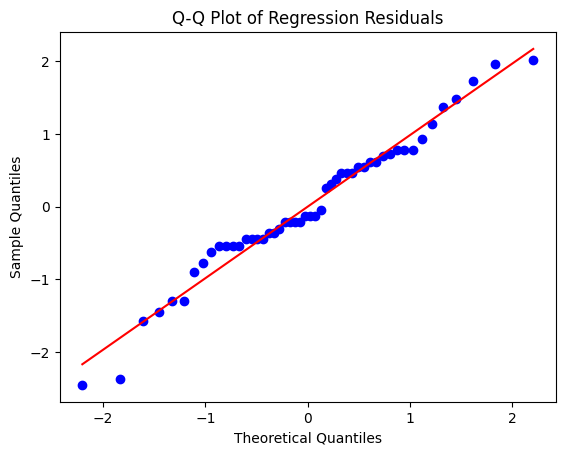

In [ ]:
import matplotlib.pyplot as plt
import scipy.stats as stats

# Get residuals
residuals = model.resid

# Q-Q Plot
stats.probplot(residuals, dist="norm", plot=plt)

plt.title("Q-Q Plot of Regression Residuals")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")
plt.show()

The Q-Q plot indicates that the regression residuals are approximately normally distributed. Most observations closely follow the reference line, with only minor deviations at the tails. Therefore, the normality assumption of the regression model is reasonably

# Shapiro-Wilk Test

In [ ]:
from scipy.stats import shapiro

stat, p = shapiro(residuals)

print("Shapiro-Wilk Statistic:", round(stat, 4))
print("p-value:", round(p, 4))

Shapiro-Wilk Statistic: 0.9741
p-value: 0.3381


## The Shapiro-Wilk test indicated that the regression residuals did not significantly deviate from normality (W = 0.974, p = 0.338). Since the p-value is greater than 0.05, the normality assumption of the regression model is reasonably satisfied.

# **Homoscedasticity**

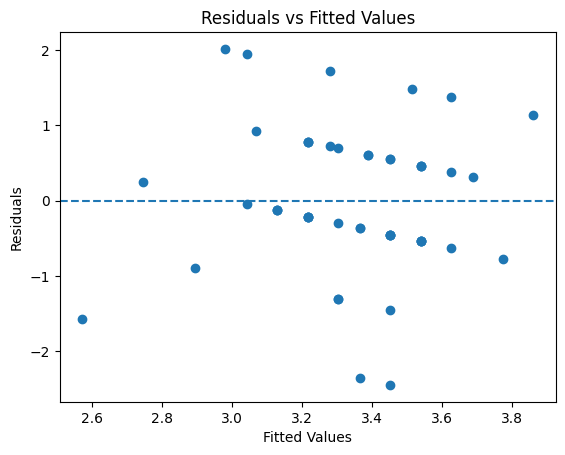

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(model.fittedvalues, model.resid)
plt.axhline(y=0, linestyle='--')

plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")
plt.show()

The Residuals vs Fitted Values plot was examined to assess the homoscedasticity assumption of the regression model. The residuals are generally scattered around the zero reference line without a clear systematic pattern. However, a slight variation in the spread of residuals can be observed across the fitted values. Overall, the plot does not indicate severe heteroscedasticity, although a statistical test was conducted for further confirmation.

# **Breusch–Pagan Test**

In [ ]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(model.resid, model.model.exog)

labels = [
    "LM Statistic",
    "LM p-value",
    "F Statistic",
    "F p-value"
]

for label, value in zip(labels, bp_test):
    print(label, ":", round(value, 4))

LM Statistic : 3.1412
LM p-value : 0.2079
F Statistic : 1.5753
F p-value : 0.2177


The Breusch–Pagan test was conducted to assess the homoscedasticity assumption of the regression model. The test produced an LM statistic of 3.1412 with a p-value of 0.2079. Since the p-value is greater than 0.05, the null hypothesis of constant residual variance is not rejected. Therefore, there is insufficient evidence of heteroscedasticity, and the homoscedasticity assumption is reasonably satisfied.

# Cook's **Distance**

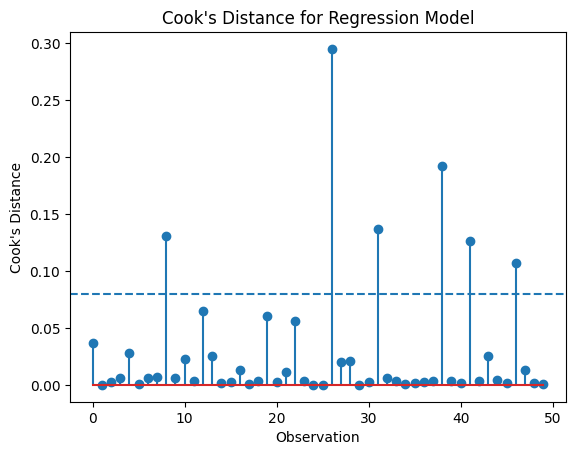

In [ ]:
import matplotlib.pyplot as plt

influence = model.get_influence()
cooks_d = influence.cooks_distance[0]

plt.stem(range(len(cooks_d)), cooks_d)
plt.axhline(y=4/len(df_analysis), linestyle='--')

plt.xlabel("Observation")
plt.ylabel("Cook's Distance")
plt.title("Cook's Distance for Regression Model")
plt.show()

Cook's Distance was examined to identify potentially influential observations in the regression model. Using the commonly applied threshold of 4/n, where n = 50, the reference value was 0.08. A few observations exceeded this threshold, indicating that they may have relatively greater influence on the regression estimates. However, exceeding the threshold does not automatically justify removing an observation; therefore, these observations should be reviewed before making any data-removal decision.

In [ ]:
threshold = 4 / len(df_analysis)

influential = pd.DataFrame({
    'Observation': range(1, len(cooks_d) + 1),
    'Cooks_Distance': cooks_d
})

influential = influential[influential['Cooks_Distance'] > threshold]

print("Threshold:", round(threshold, 4))
print(influential)

Threshold: 0.08
    Observation  Cooks_Distance
8             9        0.130515
26           27        0.294657
31           32        0.136858
38           39        0.191606
41           42        0.126235
46           47        0.106862


In [ ]:
influential_obs = [9, 27, 32, 39, 42, 47]

df_check = df_clean.iloc[[i-1 for i in influential_obs]]

display(df_check)

,Timestamp,Q1. How often do you shop online?,Q2. Have you noticed AI-based product recommendations such as “Recommended for You” or “You May Also Like”?,Q3. AI recommendations usually match my interests.,Q4. AI recommendations help me discover products that I would not have searched for myself.,Q5. AI-based product recommendations influence my decision to consider buying a product.,Q6. What would most increase your likelihood of purchasing an AI-recommended product?
8,2026/09/09 6:13:50 pm GMT+5:30,Very Frequently,"Yes , very frequently",1.0,Agree,Strongly Agree,Good reviews/ratings
27,2026/09/09 8:17:58 pm GMT+5:30,Rarely,Sometimes,1.0,Strongly Disagree,Strongly Disagree,I would not purchase based on AI recommendations
32,2026/09/09 8:38:20 pm GMT+5:30,Occasionally,Sometimes,1.0,Neutral,Strongly Agree,Detailed product information
39,2026/09/09 10:11:23 pm GMT+5:30,Very Frequently,"Yes , very frequently",1.0,Strongly Agree,Strongly Agree,Trusted brand
42,2026/09/10 10:31:04 am GMT+5:30,Frequently,Sometimes,3.0,Disagree,Strongly Agree,Good reviews/ratings
48,2026/09/10 8:45:14 pm GMT+5:30,Occasionally,"Yes , very frequently",2.0,Agree,Strongly Disagree,I would not purchase based on AI recommendations


In [ ]:
influential_obs = [9, 27, 32, 39, 42, 47]

# Remove influential observations temporarily
df_sensitivity = df_analysis.drop(
    index=[i-1 for i in influential_obs]
)

X_sens = df_sensitivity[['AI_Relevance', 'Product_Discovery']]
Y_sens = df_sensitivity['Purchase_Intention']

X_sens = sm.add_constant(X_sens)

model_sens = sm.OLS(Y_sens, X_sens).fit()

print(model_sens.summary())

                            OLS Regression Results                            
Dep. Variable:     Purchase_Intention   R-squared:                       0.065
Model:                            OLS   Adj. R-squared:                  0.020
Method:                 Least Squares   F-statistic:                     1.428
Date:                Wed, 16 Sep 2026   Prob (F-statistic):              0.251
Time:                        17:54:01   Log-Likelihood:                -61.524
No. Observations:                  44   AIC:                             129.0
Df Residuals:                      41   BIC:                             134.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 2.1971      0.67

A sensitivity analysis was conducted by temporarily excluding the six observations identified through Cook's Distance. The regression model based on the remaining 44 observations produced an R² of 0.065 compared with 0.061 in the original model. The overall model remained statistically insignificant (p = 0.251 compared with p = 0.228 in the original model). The direction and magnitude of the coefficients also remained broadly comparable. Therefore, the identified influential observations did not materially alter the overall regression conclusion, and all 50 valid observations were retained for the final analysis.